# Treemap

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Nested rectangles whose areas are proportional to values. It fits a large number of parts (and optionally a hierarchy) into a small space, and the biggest contributors stand out.

## When to use

- Show part-to-whole with many categories (10–50+) where a pie would fail
- Show hierarchical data (sector → company), coloring by the parent
- Find the dominant contributors in a long tail

## Avoid when

- Precise comparison of similar values is needed (areas are hard to compare)
- Values can be negative
- There are very few categories (use a bar chart)

## Alternatives

- Sunburst (hierarchy)
- Bar chart
- Icicle chart

## Design tips

- Color by parent group (categorical), not by a value ramp that repeats the area
- Label only rectangles large enough to hold text

## Example

A $268M equity portfolio, holdings grouped into four sectors.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import squarify
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
df = pd.DataFrame({
    "division": ["Technology"] * 5 + ["Financials"] * 3 + ["Healthcare"] * 3 + ["Energy"] * 2,
    "holding": ["Software Co", "Chipmaker", "Cloud Co", "Hardware Co", "Payments Co",
             "Big Bank", "Insurer", "Asset Mgr",
             "Pharma Co", "MedTech Co", "Biotech Co",
             "Oil Major", "Utility Co"],
    "value_m": [58, 44, 30, 26, 14, 22, 12, 6, 18, 15, 11, 7, 5],
}).sort_values(["division", "value_m"], ascending=[True, False])
df

,division,holding,value_m
11,Energy,Oil Major,7
12,Energy,Utility Co,5
5,Financials,Big Bank,22
6,Financials,Insurer,12
7,Financials,Asset Mgr,6
8,Healthcare,Pharma Co,18
9,Healthcare,MedTech Co,15
10,Healthcare,Biotech Co,11
0,Technology,Software Co,58
1,Technology,Chipmaker,44


### Plot

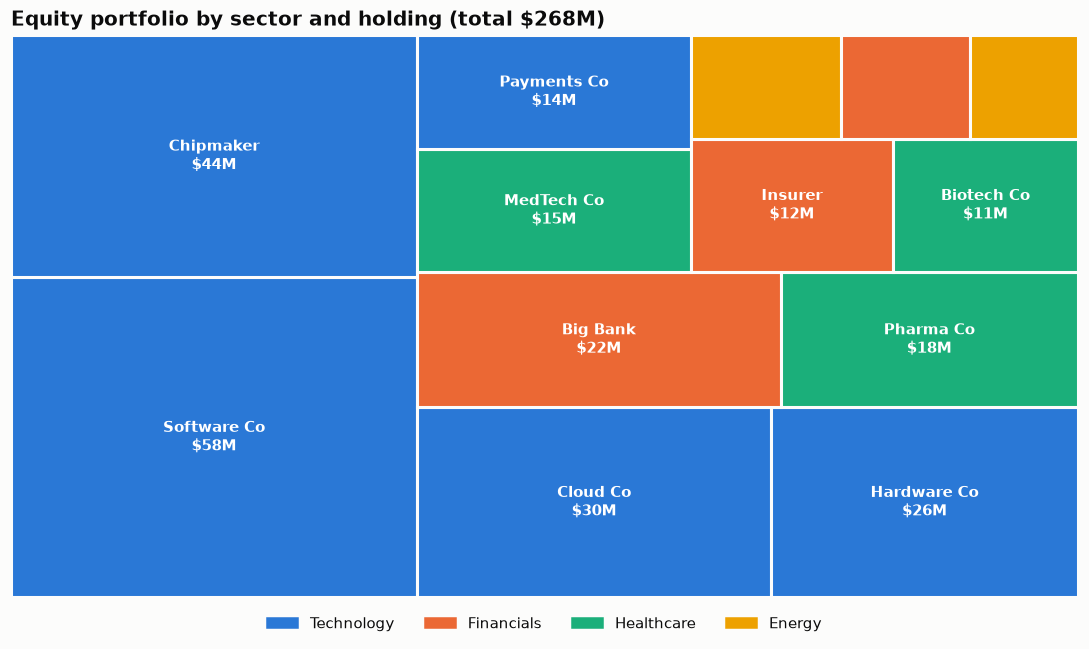

In [3]:
divisions = ["Technology", "Financials", "Healthcare", "Energy"]
cmap = dict(zip(divisions, PALETTE))
df = df.sort_values("value_m", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
labels = [f"{d}\n${v}M" if v >= 10 else "" for d, v in zip(df["holding"], df["value_m"])]
squarify.plot(sizes=df["value_m"], label=labels, color=[cmap[d] for d in df["division"]],
              ax=ax, pad=False, edgecolor="#fcfcfb", linewidth=2,
              text_kwargs=dict(color="white", fontsize=9.5, fontweight="bold"))
ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap[d]) for d in divisions]
ax.legend(handles, divisions, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.01))
ax.set_title(f"Equity portfolio by sector and holding (total ${df['value_m'].sum()}M)")
fig.tight_layout()
plt.show()

## How to read it

Each rectangle's area is a holding's market value and its color is the sector. The two largest technology holdings together make up more than a third of the portfolio, a concentration risk.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.treemap(df, path=[px.Constant("Portfolio"), "division", "holding"], values="value_m",
                 color="division", color_discrete_sequence=PALETTE,
                 title=f"Equity portfolio by sector and holding (total ${df['value_m'].sum()}M)")
fig.update_traces(root_color="#eeeeea", texttemplate="%{label}<br>$%{value}M",
                  marker=dict(line=dict(color="#fcfcfb", width=2)))
fig.update_layout(margin=dict(l=10, r=10, t=50, b=10))
fig.show()   # click a division to zoom in

---
Standalone script: [`treemap.py`](treemap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)